# Collaboration Network

### Librerie utilizzate:

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import community as community_louvain
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import random
import json

## Network Creation

### Costruzione la rete delle collaborazioni tra creators

In [2]:
# Dal file .json ottenuto nella fase di Data Gathering con struttura { nodo : { nodoConnesso : occorrenzePeso } }
# Collaborazioni totali trovate
with open('Data/collab_network.json', 'r') as f:
    collab = json.load(f)

# Dal file .json ottenuto nella fase di Data Gathering con struttura { gruppo : [ attori ] } => Audience dei creators
# Creators dai quali è stato possibile estrarre audience perchè @Handle valido
with open('Data/audience.json', 'r') as f:
    audience = json.load(f)  

G = nx.Graph()

for node, links in collab.items():

    for linked_node, weight in links.items():

        # Saranno validi solo i creators di cui è stato possibile estrarre poi anche l'audience (nessun errore di yt server)
        if node not in audience.keys() or linked_node not in audience.keys() : continue

        G.add_edge(node, linked_node, weight = weight)

network_title = "Collaborazioni tra Creator in Tendenza"

In [3]:
# Salvo il grafo per poterlo vedere su Ghepi

nx.write_gexf(G, "Networks_Gephi/collaboration.gexf")

### Disegno della rete

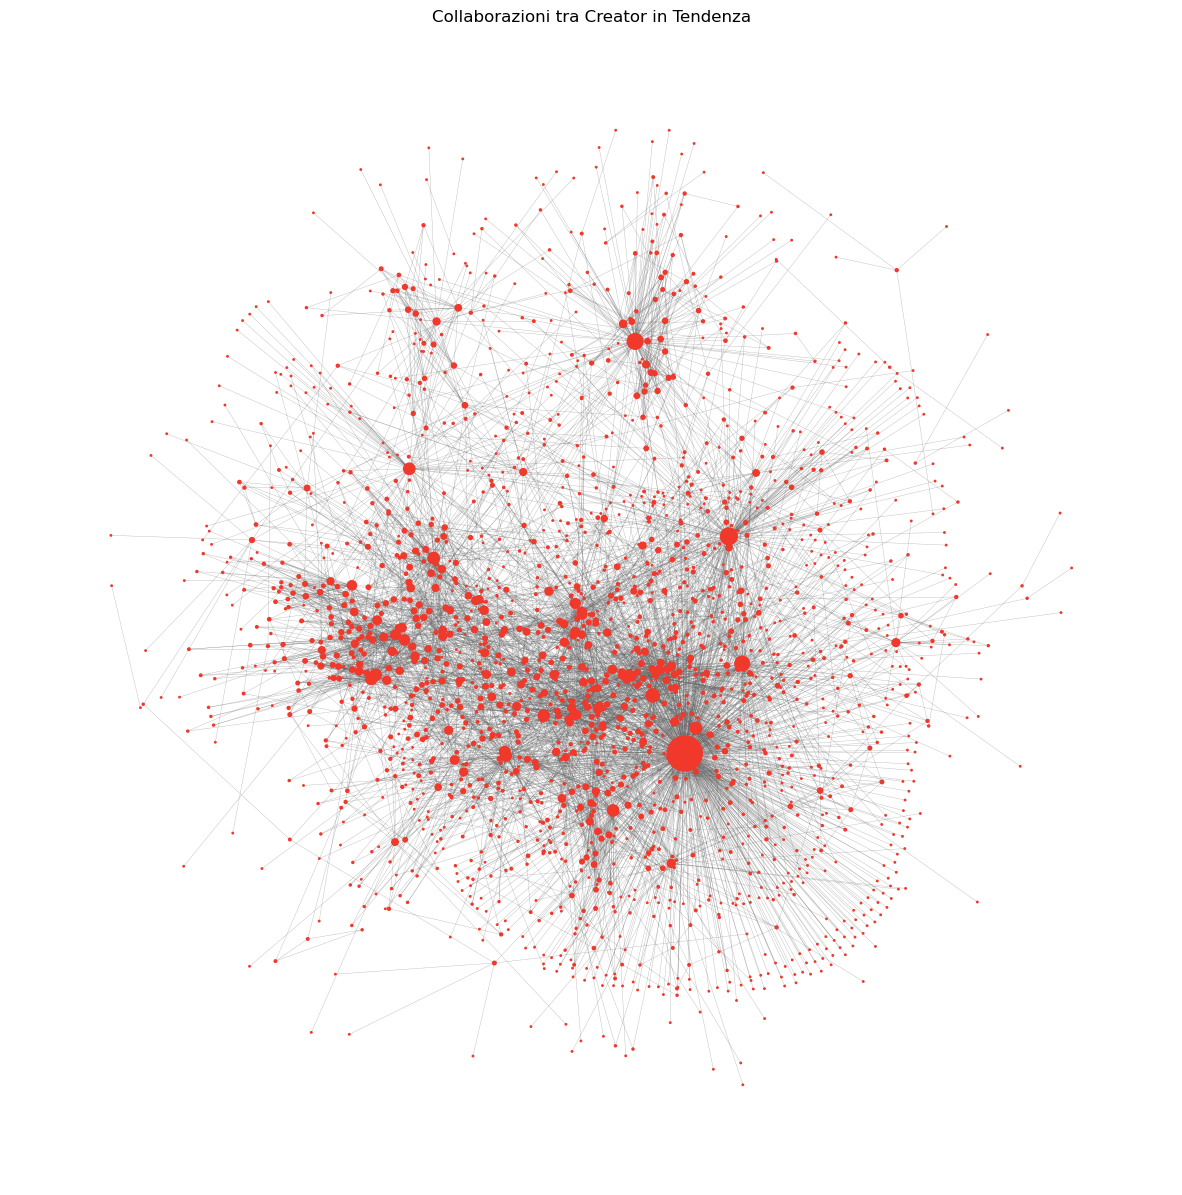

In [4]:
# Disegno della rete
pos = nx.spring_layout(G, seed=42, k=0.14)  # Seed per avere un layout riproducibile

# Grado per ciascun nodo
degree_dict = dict(G.degree(G.nodes()))

# Scala della dimensione in base al grado
node_size = [v * 1.12 for v in degree_dict.values()]

plt.figure(figsize=(15, 15))
nodes = nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color='#f0382b')
edges = nx.draw_networkx_edges(G, pos, alpha=0.5, edge_color='#616060',  width=0.25)

plt.title(network_title)
plt.axis('off')

plt.show()

## Network Analysis

### Metriche base

In [5]:
# Informazioni Grafo

print("Number of nodes:", G.number_of_nodes())

print("Number of edges:", G.number_of_edges())

print("Nodes:", list(G.edges(data=True))[:20])

Number of nodes: 2032
Number of edges: 5333
Nodes: [('eurovisionsongcontest', 'nrk', {'weight': 7}), ('eurovisionsongcontest', 'offeoffeoffe', {'weight': 1}), ('eurovisionsongcontest', 'eriantrotland', {'weight': 1}), ('eurovisionsongcontest', 'RTSPesmaEvrovizije', {'weight': 2}), ('eurovisionsongcontest', 'ollyalexander', {'weight': 1}), ('eurovisionsongcontest', 'stinkfilms', {'weight': 1}), ('eurovisionsongcontest', 'nemothings', {'weight': 1}), ('eurovisionsongcontest', 'nylanmusic', {'weight': 1}), ('eurovisionsongcontest', 'tomoehler', {'weight': 1}), ('eurovisionsongcontest', 'ellamettler', {'weight': 1}), ('eurovisionsongcontest', 'krystofdavid', {'weight': 1}), ('eurovisionsongcontest', 'nitramku', {'weight': 1}), ('eurovisionsongcontest', 'zalando', {'weight': 1}), ('eurovisionsongcontest', 'HRTDora', {'weight': 2}), ('eurovisionsongcontest', 'SanMarinoRTVOfficial', {'weight': 3}), ('eurovisionsongcontest', 'rai', {'weight': 4}), ('eurovisionsongcontest', 'LRTinklas', {'weigh

### Distribuzione del grado

In [6]:
# Gradi dei nodi
degree_sequence = np.array([degree for node, degree in G.degree()])

degree_series = pd.Series(degree_sequence)

# Calcola le statistiche
mean_degree = degree_series.mean()
min_degree = degree_series.min()
max_degree = degree_series.max()
std_degree = degree_series.std()
median_degree = degree_series.median()
density = nx.density(G)

# DataFrame con le statistiche
stats_df = pd.DataFrame({
    "Statistiche": ["Grado Medio", "Grado Minimo", "Grado Massimo", "Deviazione Standard Grado", "Mediana", "Densità"],
    "Valori": [mean_degree, min_degree, max_degree, std_degree, median_degree, density]
})

print(stats_df)

                 Statistiche      Valori
0                Grado Medio    5.249016
1               Grado Minimo    1.000000
2              Grado Massimo  569.000000
3  Deviazione Standard Grado   14.981393
4                    Mediana    2.000000
5                    Densità    0.002584


### CDF

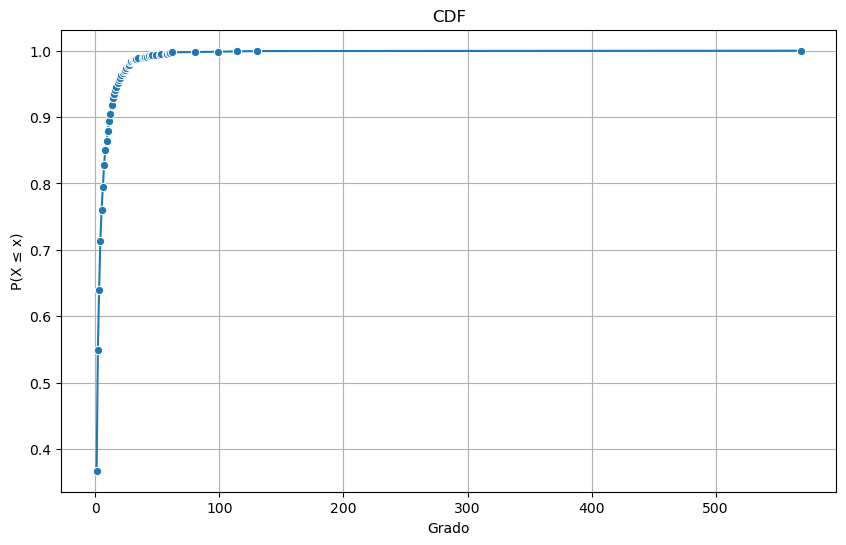

In [7]:
# CDF
degree_count = degree_series.value_counts().sort_index()
cumulative_degree_count = degree_count.cumsum() / degree_count.sum()

# Creazione grafico
plt.figure(figsize=(10, 6))
sns.lineplot(x=cumulative_degree_count.index, y=cumulative_degree_count.values, marker='o')
plt.title("CDF")
plt.xlabel("Grado")
plt.ylabel("P(X ≤ x)")
plt.grid(True)
plt.show()

### ECCDF

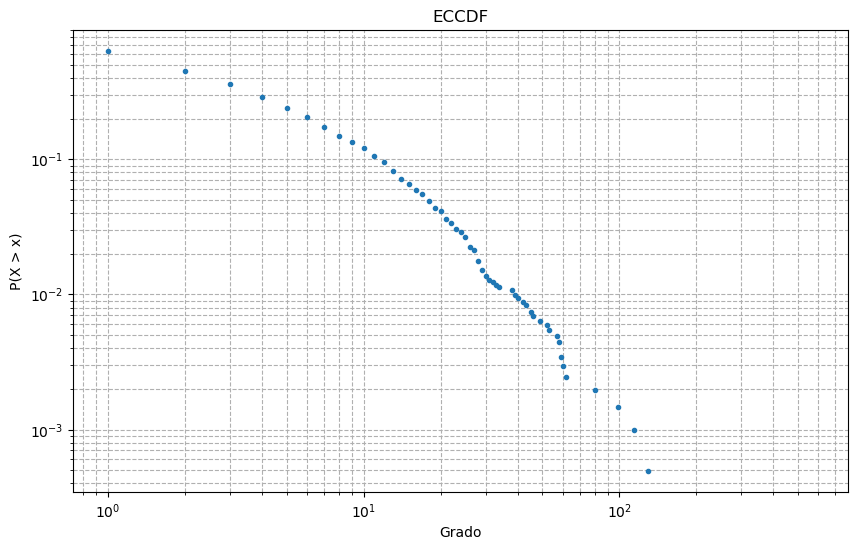

In [8]:
# ECCDF
degree_count = degree_series.value_counts().sort_index()
eccdf = 1 - degree_count.cumsum() / degree_count.sum()

# Creazione grafico
plt.figure(figsize=(10, 6))
plt.plot(eccdf.index, eccdf.values, marker='o', linestyle='none',  markersize=3)
plt.yscale('log')
plt.xscale('log')
plt.title("ECCDF")
plt.xlabel("Grado")
plt.ylabel("P(X > x)")
plt.grid(True, which="both", ls="--")
plt.show()

### Nodi Hub

In [9]:
# Dizionario dei gradi dei nodi
degree_dict = dict(G.degree())

# 99esimo percentile distribuzione del grado
percentile_99 = np.percentile(degree_sequence, 99)

# Nodi Hub (grado >= 99esimo percentile)
hub_nodes = [node for node, degree in G.degree() if degree >= percentile_99]

# Ordino i nodi hub in ordine decrescente di grado
hub_nodes_sorted = sorted(hub_nodes, key = lambda n: degree_dict[n], reverse=True)

# Stampa i nodi hub

print(f'Nodi hub (99esimo percentile): {len(hub_nodes_sorted)}')

for hub in hub_nodes_sorted:
    print(f'{hub} , {degree_dict[hub]}')


Nodi hub (99esimo percentile): 22
omarespn , 569
eurovisionsongcontest , 130
tiboinshape , 114
warnermusicitalia , 99
espndeportes , 80
Houseofhighlights , 62
jakidale , 60
petcollective , 59
albert_cancook , 59
PirlasV , 58
skysport , 57
Grax , 53
grax , 52
pirlasv , 49
federic95ita , 46
sickwolf , 45
YouTube , 45
FiusGamer , 43
iNoobChannel , 42
inoobchannel , 40
JasonDerulo , 39
lucatoselli , 39


### Misure di Centralità
- Degree Centrality
- Betweenness Centrality
- Closeness Centrality
- Eigenvector Centrality

In [10]:
# Misure di Centralità
degree_centrality = nx.degree_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G, weight='weight')
closeness_centrality = nx.closeness_centrality(G)
eigenvector_centrality = nx.eigenvector_centrality(G, max_iter=1000)

# DataFrame
centrality_df = pd.DataFrame({
    'Degree': degree_centrality,
    'Betweenness': betweenness_centrality,
    'Closeness': closeness_centrality,
    'Eigenvector': eigenvector_centrality
})

# Data una misura di centralità restituisce i top 10 nodes
def top_centrality(centrality_dict, n=10):
    return sorted(centrality_dict.items(), key=lambda item: item[1], reverse=True)[:n]

# Ottengo i top per ogni misura di centralità
top_degree = top_centrality(degree_centrality)
top_betweenness = top_centrality(betweenness_centrality)
top_closeness = top_centrality(closeness_centrality)
top_eigenvector = top_centrality(eigenvector_centrality)

# DataFrame dei top
top_df = pd.DataFrame({
    'Degree Node': [node[0] for node in top_degree],
    'Degree Centrality': [node[1] for node in top_degree],
    'Betweenness Node': [node[0] for node in top_betweenness],
    'Betweenness Centrality': [node[1] for node in top_betweenness],
    'Closeness Node': [node[0] for node in top_closeness],
    'Closeness Centrality': [node[1] for node in top_closeness],
    'Eigenvector Node': [node[0] for node in top_eigenvector],
    'Eigenvector Centrality': [node[1] for node in top_eigenvector]
})

In [11]:
# Formattazione tabella per mostrare i dati
styled_top_df = top_df.style.set_table_styles(
    [{'selector': 'th', 'props': [('font-size', '14px'), ('text-align', 'center')]},
     {'selector': 'td', 'props': [('font-size', '12px'), ('text-align', 'center')]}]
).set_properties(**{'background-color': '#f2f2f2', 'border': '1px solid black', 'color': 'black'})

styled_top_df

,Degree Node,Degree Centrality,Betweenness Node,Betweenness Centrality,Closeness Node,Closeness Centrality,Eigenvector Node,Eigenvector Centrality
0,omarespn,0.280158,omarespn,0.512269,omarespn,0.349558,omarespn,0.679569
1,eurovisionsongcontest,0.064008,MrBeast,0.112663,MrBeast,0.330215,espndeportes,0.127347
2,tiboinshape,0.056130,eurovisionsongcontest,0.110791,Houseofhighlights,0.316327,Houseofhighlights,0.113682
3,warnermusicitalia,0.048744,tiboinshape,0.090120,espndeportes,0.313541,ESPNFC,0.060143
4,espndeportes,0.039389,warnermusicitalia,0.088862,YouTube,0.309548,espnfc,0.060143
5,Houseofhighlights,0.030527,dimitri_houles,0.066335,NFL,0.304395,NFL,0.059231
6,jakidale,0.029542,dylendror,0.057711,fcbarcelona,0.303607,MrBeast,0.051479
7,petcollective,0.029050,NoaKirelOfficial,0.056951,fcbayern,0.302042,NBA,0.047175
8,albert_cancook,0.029050,fcbayern,0.056822,redbull,0.296957,mlb,0.046331
9,PirlasV,0.028557,petcollective,0.048152,Luca,0.295154,dudeperfect,0.045974


### Matrice di Correlazione
Visualizzata come Heatmap

               Degree  Betweenness  Closeness  Eigenvector
Degree       1.000000     0.909378   0.184112     0.595472
Betweenness  0.909378     1.000000   0.170307     0.652584
Closeness    0.184112     0.170307   1.000000     0.492026
Eigenvector  0.595472     0.652584   0.492026     1.000000


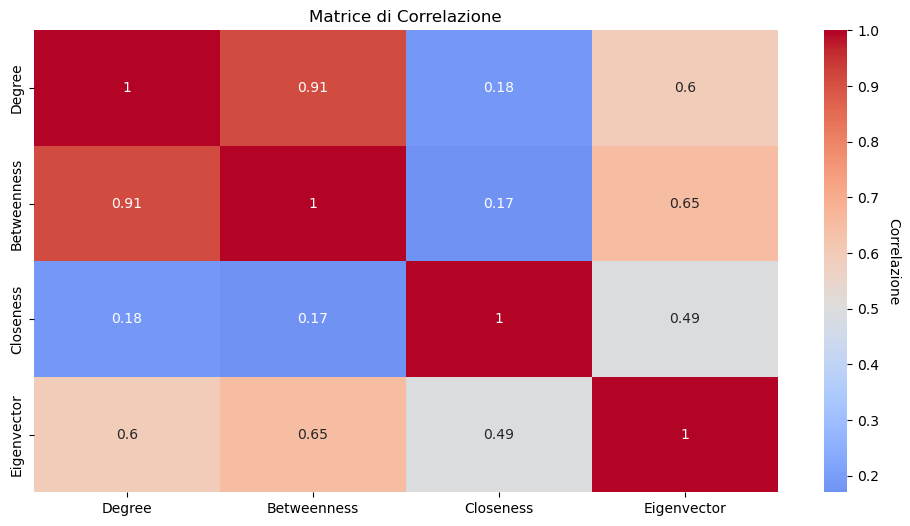

In [12]:
# Matrice di Correlazione
correlation_matrix = centrality_df.corr()

# Stampa la matrice di correlazione per verifica
print(correlation_matrix)

# Visualizzazione Heatmap
plt.figure(figsize=(12, 6))
ax = sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0.5, cbar_kws={"orientation": "vertical"})
plt.title('Matrice di Correlazione')

# Legenda dei colori in verticale
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.ax.set_ylabel('Correlazione', rotation=270, labelpad=15)

plt.show()

### Connettività

In [13]:
# Analisi delle componenti connesse
connected_components = list(nx.connected_components(G))
num_connected_components = len(connected_components)
largest_cc = max(connected_components, key=len)

# Grandezza media delle componenti connesse escluse da quella più grande
sizes_of_other_components = [len(component) for component in connected_components if component != largest_cc]
average_size_other_components = sum(sizes_of_other_components) / len(sizes_of_other_components) if sizes_of_other_components else 0

print("Numero di componenti connesse:", num_connected_components)
print("Dimensione della componente connessa più grande:", len(largest_cc))
print("Grandezza media delle componenti connesse escluse da quella più grande:", average_size_other_components)

Numero di componenti connesse: 8
Dimensione della componente connessa più grande: 2013
Grandezza media delle componenti connesse escluse da quella più grande: 2.7142857142857144


### Transitività
- Bridges
- Local Bridges
- Almost Local Bridges - soglia = 4
- Global Clustering Coefficient
- Triangles
- Local Clustering Coefficient

In [14]:
# Bridges
bridges = list(nx.bridges(G))
num_bridges = len(bridges)

# Local Bridges
def local_bridges(G):
    local_bridges_list = []
    for u, v in G.edges():
        G_copy = G.copy()
        G_copy.remove_edge(u, v)
        if nx.has_path(G_copy, u, v):
            if nx.shortest_path_length(G_copy, source=u, target=v) > 2:
                local_bridges_list.append((u, v))
    return local_bridges_list

local_bridges_list = local_bridges(G)
num_local_bridges = len(local_bridges_list)

# Almost Local Bridges
def almost_local_bridges(G, threshold):
    almost_local_bridges_list = []
    for u, v in G.edges():
        G_copy = G.copy()
        G_copy.remove_edge(u, v)
        if nx.has_path(G_copy, u, v):
            distance = nx.shortest_path_length(G_copy, source=u, target=v)
            if distance > 2 and distance <= threshold:
                almost_local_bridges_list.append((u, v))
    return almost_local_bridges_list

# Calcolo con soglia 4
almost_local_bridges_list = almost_local_bridges(G, 4)
num_almost_local_bridges = len(almost_local_bridges_list)

# Global Clustering Coefficient
global_clustering = nx.transitivity(G)

# Triangles
triangles = sum(nx.triangles(G).values()) // 3

# Average Clustering Coefficient
average_clustering = nx.average_clustering(G)

print("Numero di ponti:", num_bridges)
print("Numero di ponti locali:", num_local_bridges)
print("Numero di quasi ponti locali (soglia = 4):", num_almost_local_bridges)
print("Clustering Globale:", global_clustering)
print("Numero di Triangoli:", triangles)
print("Clustering Medio:", average_clustering)

Numero di ponti: 752
Numero di ponti locali: 1079
Numero di quasi ponti locali (soglia = 4): 987
Clustering Globale: 0.05083386210446921
Numero di Triangoli: 4246
Clustering Medio: 0.2505071683022526


### Assortatività del Grado del Nodo

In [15]:
# Assortatività del grado del nodo
degree_assortativity = nx.degree_assortativity_coefficient(G)
print("Assortatività del Grado del Nodo:", degree_assortativity)

Assortatività del Grado del Nodo: -0.12258014071796088


### Community Detection

Modularità della partizione: 0.8510593533408641
Numero di comunità rilevate: 32


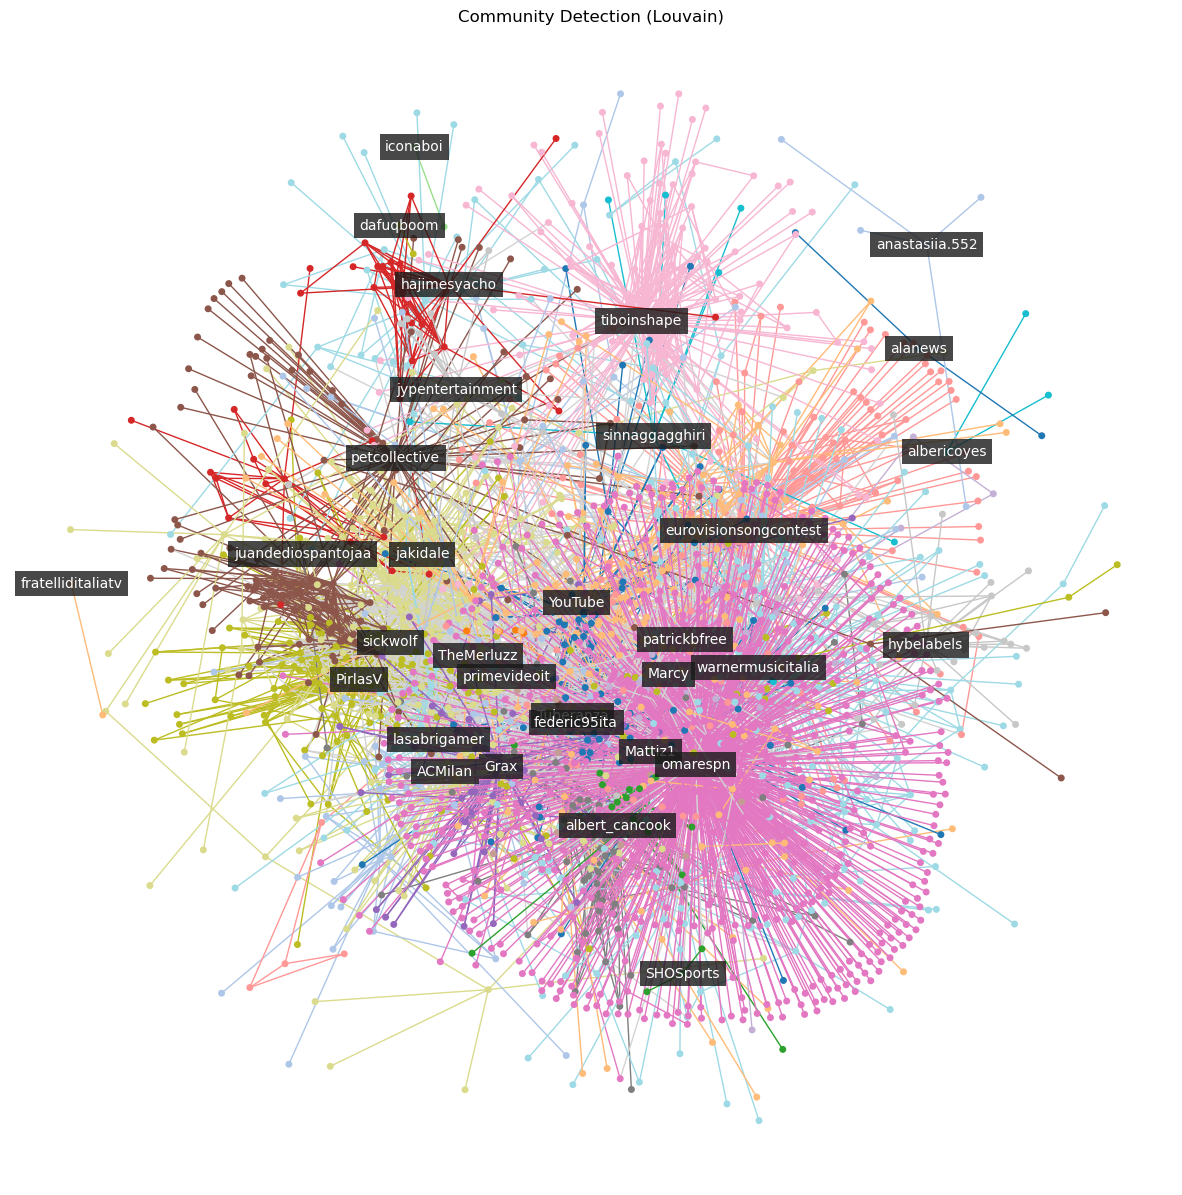

In [20]:
# Rilevamento Communities con Louvain
partition = community_louvain.best_partition(G)

# Modularità della partizione
modularity = community_louvain.modularity(partition, G)
print("Modularità della partizione:", modularity)

num_communities = len(set(partition.values()))
print("Numero di comunità rilevate:", num_communities)

# Aggiungo il risultato della rilevazione delle comunità come attributo del nodo
nx.set_node_attributes(G, partition, 'community')

# Nodo con il grado più alto in ciascuna comunità
community_max_degree_nodes = {}
for community in set(partition.values()):
    nodes_in_community = [node for node in partition if partition[node] == community]
    max_degree_node = max(nodes_in_community, key=lambda node: G.degree(node))
    community_max_degree_nodes[max_degree_node] = community

# Colore casuale per ciascuna comunità
colors = list(plt.get_cmap('tab20').colors)
random.shuffle(colors)
community_colors = {community: colors[i % len(colors)] for i, community in enumerate(set(partition.values()))}

# Disegno della rete colorata per comunità
pos = nx.spring_layout(G, seed=42, k=0.14)  # k controlla la distanza tra i nodi

plt.figure(figsize=(15, 15))

# Archi del colore della Community
for edge in G.edges(data=True):
    node1, node2 = edge[:2]
    community1 = partition[node1]
    community2 = partition[node2]
    edge_color = community_colors[community1] if community1 == community2 else 'lightgray'
    nx.draw_networkx_edges(G, pos, edgelist=[(node1, node2)], edge_color=edge_color, alpha=1)

# Nodi colori della Community
node_colors = [community_colors[partition[node]] for node in G.nodes()]
nodes = nx.draw_networkx_nodes(G, pos, node_size=16, node_color=node_colors)

# Aggiunggo le etichette ai nodi con il grado più alto in ciascuna comunità
labels = {node: node for node in community_max_degree_nodes.keys()}
nx.draw_networkx_labels(G, pos, labels, font_size=10, font_color='white', bbox=dict(facecolor='#191a19', edgecolor='none', alpha=0.8))

plt.title("Community Detection (Louvain)")
plt.axis('off')
plt.show()

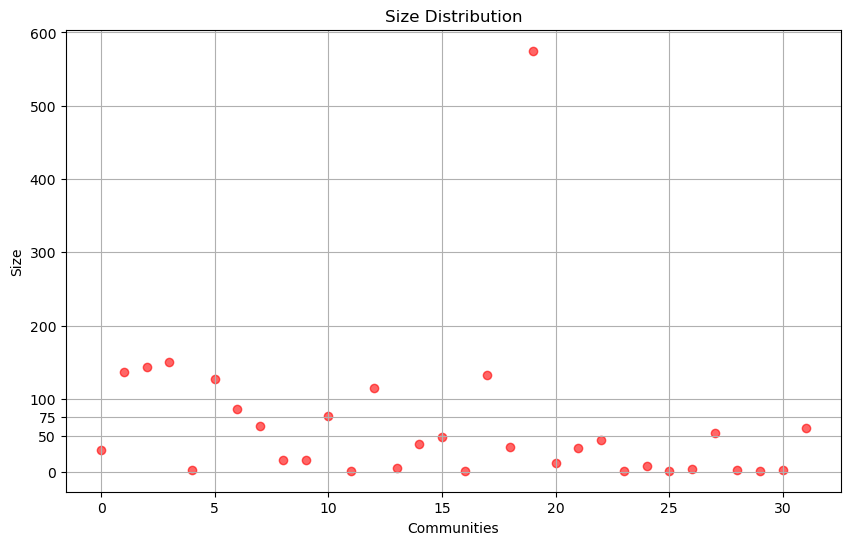

In [21]:
# Calcolo della dimensione di ciascuna comunità
community_sizes = [list(partition.values()).count(community) for community in set(partition.values())]

# DataFrame
community_df = pd.DataFrame({
    'Communities': range(num_communities),
    'Size': community_sizes
})

# Distribuzione delle dimensioni delle comunità
plt.figure(figsize=(10, 6))
plt.scatter(community_df['Communities'], community_df['Size'], color='red', alpha=0.6)
plt.title('Size Distribution')
plt.xlabel('Communities') # Communities
plt.ylabel('Size') # Size

plt.yticks([0, 50, 75, 100, 200, 300, 400, 500, 600]) # Valori asse y 'custom' per una migliore visualizzazione

plt.grid(True)
plt.show()

In [22]:
# Salvato dizionario partition in un file JSON
with open('Data/partition.json', 'w') as f:
    json.dump(partition, f)